In [1]:
%reload_ext autoreload
%autoreload 2
import sys

sys.path.insert(0, r"C:\\Users\\101al\\Desktop\\codex")

import qiskit_metal as metal
from qiskit_metal import designs, draw
from qiskit_metal import MetalGUI, Dict


In [2]:
FC_design = designs.DesignFlipChip()
FC_design.metadata['design_name'] = 'FC_tlines_check'
gui = MetalGUI(FC_design)
FC_design.overwrite_enabled = True

chip2chip_spacing = '10um'
FC_design.chips['C_chip'] = Dict(
    material='silicon',
    layer_start='0',
    layer_end='2048',
    size=Dict(
        center_x='0.0mm',
        center_y='0.0mm',
        center_z='0.0mm',
        size_x='10mm',
        size_y='10mm',
        size_z='-525um'
    )
)
FC_design.chips['Q_chip'] = Dict(
    material='silicon',
    layer_start='0',
    layer_end='2048',
    size=Dict(
        center_x='0.0mm',
        center_y='0.0mm',
        center_z=FC_design.parse_value(FC_design.chips['C_chip'].size.center_z) + FC_design.parse_value(chip2chip_spacing),
        size_x='9mm',
        size_y='9mm',
        size_z='525um'
    )
)


In [11]:
def preview_route(module_name, class_name, name=None, options=None):
    FC_design.delete_all_components()
    module = __import__(f'fc_usercomponents.{module_name}', fromlist=[class_name])
    cls = getattr(module, class_name)
    component_name = name or module_name
    base_options = dict(
        chip='C_chip',
        layer=1,
        trace_width='10um',
        trace_gap='6um',
        fillet='120um',
        total_length='2mm',
        pin_inputs=Dict(
            start_pin=Dict(component='start_pad', pin='open'),
            end_pin=Dict(component='end_pad', pin='open')
        ),
        lead=Dict(start_straight='100um', end_straight='100um'),
        carve_out_chip='Q_chip',
        carve_out_extend_size='10um'
    )
    if options:
        base_options.update(options)

    from qiskit_metal.qlibrary.terminations.open_to_ground import OpenToGround
    start_pad = OpenToGround(FC_design, 'start_pad', options=dict(pos_x='-1mm', pos_y='0mm', orientation='0', width='40um'))
    end_pad = OpenToGround(FC_design, 'end_pad', options=dict(pos_x='1mm', pos_y='0mm', orientation='180', width='40um'))

    component = cls(FC_design, component_name, options=base_options)
    gui.rebuild()
    gui.autoscale()
    return component


12:54AM 22s WARNING [check_lengths]: For path table, component=anchored_path, key=trace has short segments that could cause issues with fillet. Values in (1-1) (6-6)  are index(es) in shapely geometry.
12:54AM 22s WARNING [check_lengths]: For path table, component=anchored_path, key=cut has short segments that could cause issues with fillet. Values in (1-1) (6-6)  are index(es) in shapely geometry.
12:54AM 22s WARNING [check_lengths]: For path table, component=anchored_path, key=top_carveout has short segments that could cause issues with fillet. Values in (1-1) (6-6)  are index(es) in shapely geometry.
12:54AM 22s WARNING [check_lengths]: For path table, component=anchored_path, key=trace has short segments that could cause issues with fillet. Values in (1-1) (6-6)  are index(es) in shapely geometry.
12:54AM 22s WARNING [check_lengths]: For path table, component=anchored_path, key=cut has short segments that could cause issues with fillet. Values in (1-1) (6-6)  are index(es) in shape

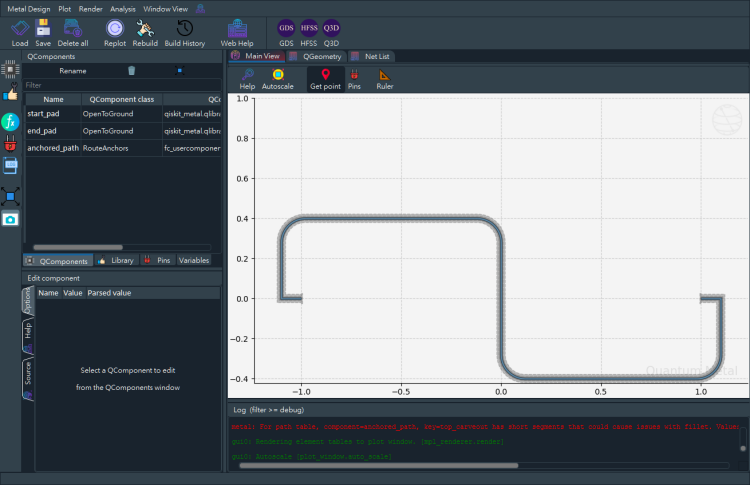

In [19]:
import numpy as np

preview_route(
    'anchored_path', 
    'RouteAnchors', 
    options=dict(
        anchors=Dict(
            a0=np.array([0.0, 0.4]), 
            a1=np.array([0.0, -0.4])
        )
    )
)
gui.screenshot()

12:48AM 55s WARNING [check_lengths]: For path table, component=framed_path, key=trace has short segments that could cause issues with fillet. Values in (1-4)  are index(es) in shapely geometry.
12:48AM 55s WARNING [check_lengths]: For path table, component=framed_path, key=cut has short segments that could cause issues with fillet. Values in (1-4)  are index(es) in shapely geometry.
12:48AM 55s WARNING [check_lengths]: For path table, component=framed_path, key=top_carveout has short segments that could cause issues with fillet. Values in (1-4)  are index(es) in shapely geometry.
12:48AM 55s WARNING [check_lengths]: For path table, component=framed_path, key=trace has short segments that could cause issues with fillet. Values in (1-4)  are index(es) in shapely geometry.
12:48AM 55s WARNING [check_lengths]: For path table, component=framed_path, key=cut has short segments that could cause issues with fillet. Values in (1-4)  are index(es) in shapely geometry.
12:48AM 55s WARNING [check_

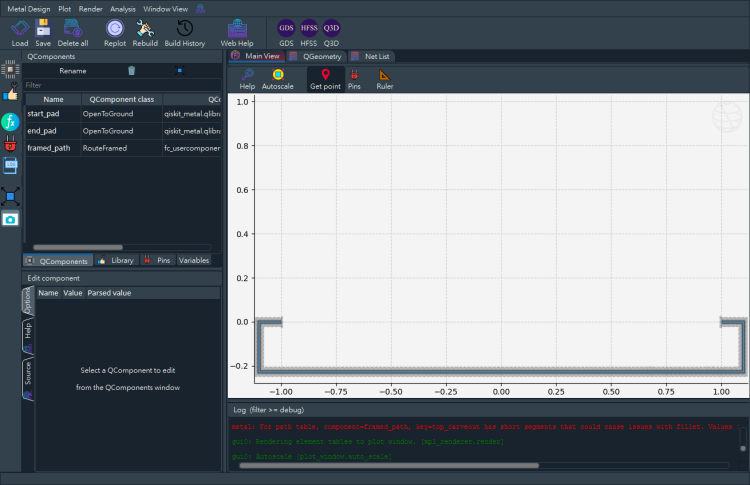

In [13]:
preview_route('framed_path', 'RouteFramed')
gui.screenshot()

12:48AM 56s WARNING [check_lengths]: For path table, component=meandered, key=trace has short segments that could cause issues with fillet. Values in (1-22)  are index(es) in shapely geometry.
12:48AM 56s WARNING [check_lengths]: For path table, component=meandered, key=cut has short segments that could cause issues with fillet. Values in (1-22)  are index(es) in shapely geometry.
12:48AM 56s WARNING [check_lengths]: For path table, component=meandered, key=top_carveout has short segments that could cause issues with fillet. Values in (1-22)  are index(es) in shapely geometry.
12:48AM 56s WARNING [check_lengths]: For path table, component=meandered, key=trace has short segments that could cause issues with fillet. Values in (1-22)  are index(es) in shapely geometry.
12:48AM 56s WARNING [check_lengths]: For path table, component=meandered, key=cut has short segments that could cause issues with fillet. Values in (1-22)  are index(es) in shapely geometry.
12:48AM 56s WARNING [check_lengt

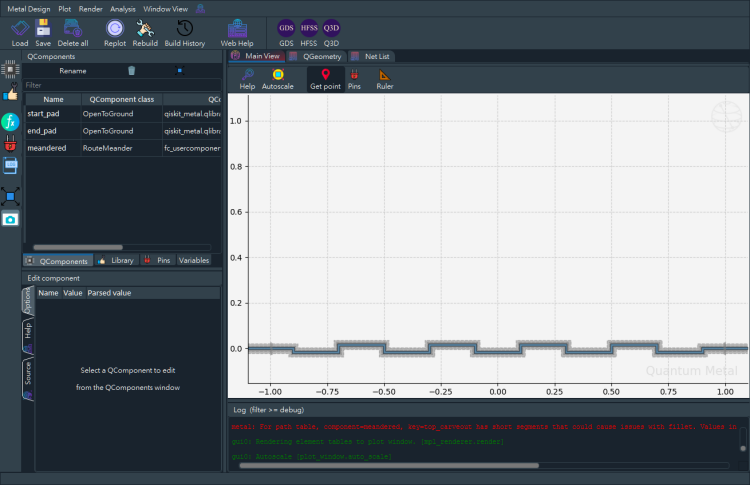

In [14]:
preview_route('meandered', 'RouteMeander', options=dict(meander=Dict(spacing='200um', asymmetry='0um')))
gui.screenshot()

12:55AM 21s WARNING [check_lengths]: For path table, component=mixed_path, key=trace has short segments that could cause issues with fillet. Values in (1-1) (6-6)  are index(es) in shapely geometry.
12:55AM 21s WARNING [check_lengths]: For path table, component=mixed_path, key=cut has short segments that could cause issues with fillet. Values in (1-1) (6-6)  are index(es) in shapely geometry.
12:55AM 21s WARNING [check_lengths]: For path table, component=mixed_path, key=top_carveout has short segments that could cause issues with fillet. Values in (1-1) (6-6)  are index(es) in shapely geometry.
12:55AM 21s WARNING [check_lengths]: For path table, component=mixed_path, key=trace has short segments that could cause issues with fillet. Values in (1-1) (6-6)  are index(es) in shapely geometry.
12:55AM 21s WARNING [check_lengths]: For path table, component=mixed_path, key=cut has short segments that could cause issues with fillet. Values in (1-1) (6-6)  are index(es) in shapely geometry.
12

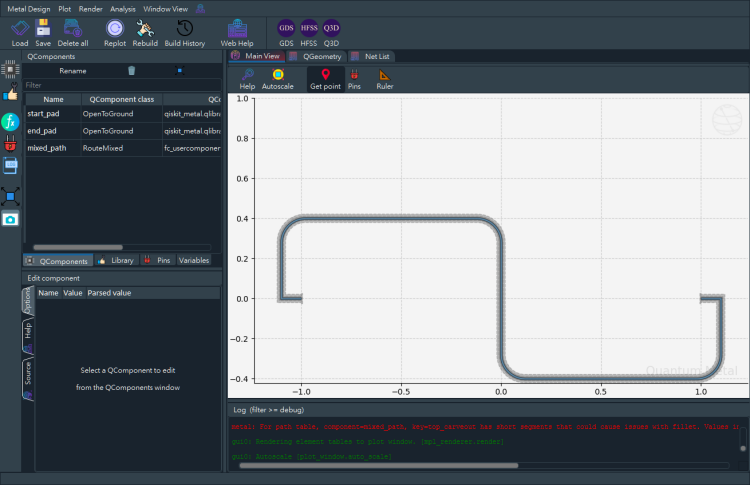

In [20]:
preview_route('mixed_path', 'RouteMixed', options=dict(
        anchors=Dict(
            a0=np.array([0.0, 0.4]), 
            a1=np.array([0.0, -0.4])
        )
    ))
gui.screenshot()

12:56AM 34s WARNING [check_lengths]: For path table, component=pathfinder, key=trace has short segments that could cause issues with fillet. Values in (1-1) (6-6)  are index(es) in shapely geometry.
12:56AM 34s WARNING [check_lengths]: For path table, component=pathfinder, key=cut has short segments that could cause issues with fillet. Values in (1-1) (6-6)  are index(es) in shapely geometry.
12:56AM 34s WARNING [check_lengths]: For path table, component=pathfinder, key=top_carveout has short segments that could cause issues with fillet. Values in (1-1) (6-6)  are index(es) in shapely geometry.
12:56AM 34s WARNING [check_lengths]: For path table, component=pathfinder, key=trace has short segments that could cause issues with fillet. Values in (1-1) (6-6)  are index(es) in shapely geometry.
12:56AM 34s WARNING [check_lengths]: For path table, component=pathfinder, key=cut has short segments that could cause issues with fillet. Values in (1-1) (6-6)  are index(es) in shapely geometry.
12

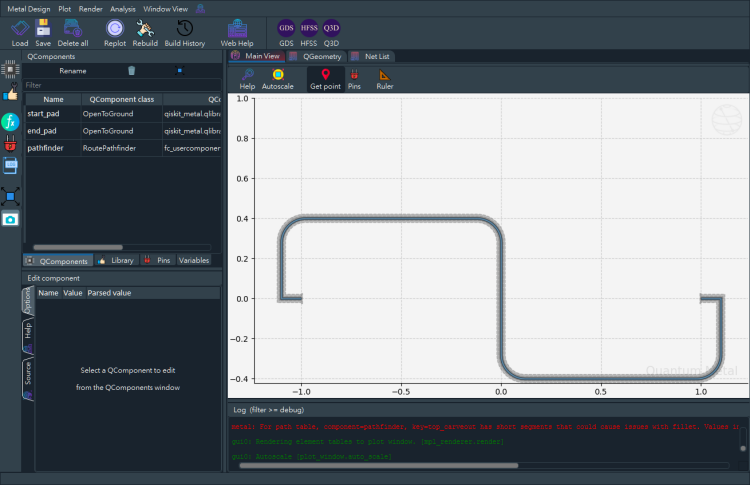

In [24]:
preview_route('pathfinder', 'RoutePathfinder', options=dict(
        anchors=Dict(
            a0=np.array([0.0, 0.4]), 
            a1=np.array([0.0, -0.4])
        )
    ))
gui.screenshot()

12:49AM 03s WARNING [check_lengths]: For path table, component=straight_path, key=trace has short segments that could cause issues with fillet. Values in (1-2)  are index(es) in shapely geometry.
12:49AM 03s WARNING [check_lengths]: For path table, component=straight_path, key=cut has short segments that could cause issues with fillet. Values in (1-2)  are index(es) in shapely geometry.
12:49AM 03s WARNING [check_lengths]: For path table, component=straight_path, key=top_carveout has short segments that could cause issues with fillet. Values in (1-2)  are index(es) in shapely geometry.
12:49AM 03s WARNING [check_lengths]: For path table, component=straight_path, key=trace has short segments that could cause issues with fillet. Values in (1-2)  are index(es) in shapely geometry.
12:49AM 03s WARNING [check_lengths]: For path table, component=straight_path, key=cut has short segments that could cause issues with fillet. Values in (1-2)  are index(es) in shapely geometry.
12:49AM 03s WARNI

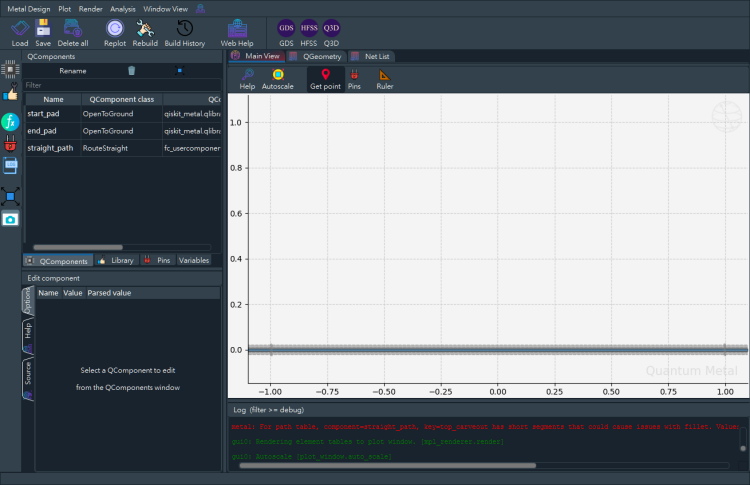

In [17]:
preview_route('straight_path', 'RouteStraight')
gui.screenshot()